Training
0 2.3026 12.13
50 1.9781 59.230000000000004
100 0.9422 78.57
150 0.6211 84.41
200 0.501 87.06
250 0.4394 88.32
300 0.4024 89.05
350 0.3778 89.56
400 0.36 89.95
450 0.3461 90.25999999999999


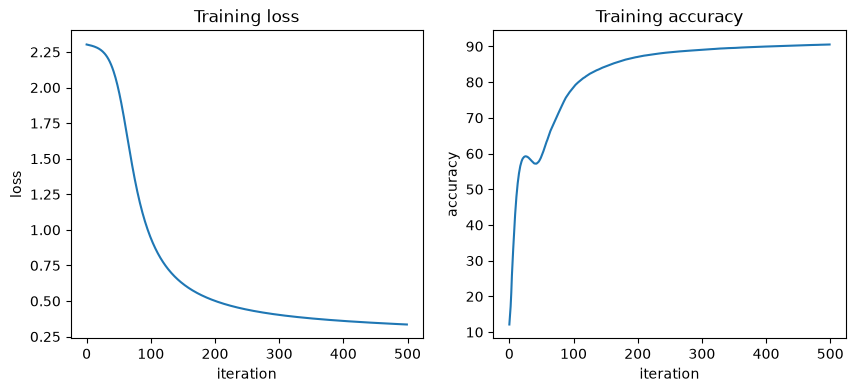

Testing
Test accuracy: 90.72


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Training")
data=np.array(pd.read_csv("/Users/yuktaranjalkar/Downloads/mnist_train.csv"))

y=data[:,0]
x=data[:, 1:]/255.0

def param():
    w1=np.random.randn(784,128)*0.01
    w2=np.random.randn(128,10)*0.01
    b1=np.zeros((1,128))
    b2=np.zeros((1,10))
    return w1,w2,b1,b2

def relu(z):
    return np.maximum(0, z)

def softmax(z):
    expZ=np.exp(z-np.max(z, axis=1, keepdims=True))
    return expZ/np.sum(expZ, axis=1, keepdims=True)

def onehot(y):
    Y=np.zeros((y.size,10))
    Y[np.arange(y.size),y]=1
    return Y

def cross_entropy(a2,Y):
    m=Y.shape[0]
    return -np.sum(Y*np.log(a2+1e-9))/m

def forward(x,w1,w2,b1,b2):
    z1=x@w1+b1
    a1=relu(z1)
    z2=a1@w2+b2
    a2=softmax(z2)
    return z1, z2, a1, a2

def backward(x,y,z1,a1,a2,w2):
    m=x.shape[0]
    dz2=a2-y
    dw2=a1.T@dz2/m
    db2=np.sum(dz2,axis=0, keepdims=True)/m
    da1=dz2@w2.T
    dz1=da1*(z1>0)
    dw1 = x.T @ dz1 / m
    db1=np.sum(dz1,axis=0, keepdims=True)/m
    return dw1, dw2, db1, db2

def update(w1,w2,b1,b2,dw1,dw2,db1,db2):
    w1=w1-0.1*dw1
    w2=w2-0.1*dw2
    b1=b1-0.1*db1
    b2=b2-0.1*db2
    return w1,w2,b1,b2

Y=onehot(y)
w1,w2,b1,b2=param()

losses=[]
accs=[]

for i in range(500):
    z1,z2,a1,a2=forward(x,w1,w2,b1,b2)
    loss=cross_entropy(a2, Y)
    acc=np.mean(np.argmax(a2, axis=1)==y)
    losses.append(loss)
    accs.append(acc*100)

    dw1,dw2,db1,db2=backward(x,Y,z1,a1,a2,w2)
    w1,w2,b1,b2=update(w1,w2,b1,b2,dw1,dw2,db1,db2)

    if i%50==0:
        print(i, round(loss,4), round(acc,4)*100)


plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(losses)
plt.xlabel("iteration")
plt.ylabel("loss")
plt.title("Training loss")

plt.subplot(1,2,2)
plt.plot(accs)
plt.xlabel("iteration")
plt.ylabel("accuracy")
plt.title("Training accuracy")

plt.show()

print("Testing")

testdata=np.array(pd.read_csv("/Users/yuktaranjalkar/Downloads/mnist_test.csv"))

yt=testdata[:,0]
xt=testdata[:,1:]/255.0

z1t,z2t,a1t,a2t=forward(xt,w1,w2,b1,b2)


test_acc = np.mean(np.argmax(a2t, axis=1) == yt)
print("Test accuracy:", round(test_acc, 4)*100)
